# Parcial 3: RNN, LSTM y CNN→LSTM sobre UCI HAR

**Autor:** completar · **Curso:** Deep Learning · **Fecha:** completar.

**Pregunta:** ¿qué arquitectura generaliza mejor a sujetos no observados usando señales temporales y un protocolo común?

No se presupone que CNN→LSTM gane. La métrica principal es **F1 macro**. El informe compara las configuraciones seleccionadas en dev; test solo describe su desempeño final. Este notebook documenta el experimento ejecutado con los scripts del proyecto.

In [1]:
from pathlib import Path
import sys, json, subprocess
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Abre el notebook desde el proyecto"
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Image
from har.data import download, load_official, split_by_subject, LABELS, CHANNELS
from har.experiment import configurations
from har.models import HARModel
CFG = json.loads((ROOT / "configs/overnight.json").read_text())
OUT = ROOT / "runs/overnight"
ANALYSIS = OUT / "analysis"
print("PyTorch:", torch.__version__, "CUDA:", torch.cuda.is_available())
print("Resultados:", OUT)

PyTorch: 2.15.0+cpu CUDA: False
Resultados: /home/nuvu-pc-n4gx/Personal/University/Deep-learning/Parcial 3/runs/overnight


## 1. Datos y prevención de fuga

[UCI HAR](https://doi.org/10.24432/C54S4K) contiene seis actividades y señales a 50 Hz. Usamos las ventanas temporales preprocesadas por los autores: 128 muestras × 9 canales; no las 561 características derivadas.

El 50% de solapamiento vuelve inadecuada una partición aleatoria por ventanas. Conservamos los nueve sujetos oficiales de test y reservamos cinco sujetos del train oficial para dev. No se consultan señales ni etiquetas test en esta exploración. Tener sujetos distintos es una evaluación de generalización entre personas, no una garantía de distribuciones idénticas.

,split,ventanas,sujetos,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
0,train,5511,"[1, 3, 6, 7, 8, 11, 14, 15, 17, 19, 22, 23, 25...",948,812,739,954,1013,1045
1,dev,1841,"[5, 16, 21, 28, 30]",278,261,247,332,361,362


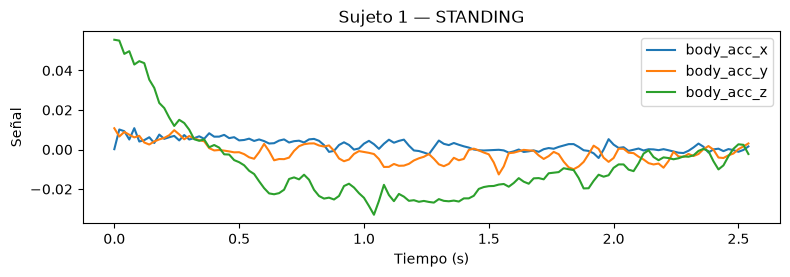

In [2]:
download(ROOT / "data")  # Usa la descarga local si ya existe.
x, y, subjects = load_official(ROOT / "data", "train")
parts = split_by_subject(x, y, subjects, CFG["dev_subjects"])
rows = []
for split, (sx, sy, ss, indices) in parts.items():
    rows.append({"split": split, "ventanas": len(sy), "sujetos": sorted(map(int, set(ss))),
                 **{LABELS[i]: int((sy == i).sum()) for i in range(6)}})
display(pd.DataFrame(rows))
assert set(parts["train"][2]).isdisjoint(parts["dev"][2])
fig, ax = plt.subplots(figsize=(9, 2.5))
i = 0
for c in range(3):
    ax.plot(np.arange(128)/50, x[i,:,c], label=CHANNELS[c])
ax.set(xlabel="Tiempo (s)", ylabel="Señal", title=f"Sujeto {subjects[i]} — {LABELS[y[i]]}")
ax.legend(); plt.show()

## 2. Protocolo y referencias

- F1 macro = promedio del F1 de las seis clases; accuracy es secundaria.
- La estandarización por canal se ajusta solo sobre train y sobre el contexto elegido.
- Contextos 64/128: se recorta el **sufijo** de ventanas existentes, manteniendo los mismos ejemplos y particiones.
- Referencias: clase mayoritaria y regresión logística sobre media, desviación, mínimo y máximo de nueve canales (36 atributos, contexto 128).
- La referencia no estima el error óptimo/humano. No permite cuantificar sesgo evitable.
- Todo ajuste y early stopping se decide con dev. Test se abre solo después de fijar los checkpoints finales.

Esta organización aplica los capítulos 5–12 de *Machine Learning Yearning*.

In [3]:
for name in ("majority", "logistic"):
    p = OUT / "baselines" / f"{name}.json"
    if p.exists():
        print(name)
        display(pd.DataFrame(json.loads(p.read_text())).T)
    else:
        print(f"{name}: se ajustará antes de comenzar la búsqueda nocturna.")

majority: se ajustará antes de comenzar la búsqueda nocturna.
logistic: se ajustará antes de comenzar la búsqueda nocturna.


## 3. Arquitecturas e hiperparámetros

RNN y LSTM usan su último estado oculto. CNN→LSTM extrae patrones con Conv1D (kernel 5, 32 canales), ReLU y MaxPool antes de procesar la secuencia. Las tres usan dropout explícito y una salida lineal de seis logits.

El espacio y los ejemplos son compartidos, pero la cantidad de parámetros cambia. Se fija una referencia inicial y se muestrean otras 15 configuraciones sin repetición. Cada arquitectura se ajusta por separado usando únicamente F1 macro dev. Después se repite cada configuración ganadora con tres semillas nuevas, sin elegir una semilla por test.

In [4]:
plan = configurations(CFG)
display(pd.DataFrame(plan))
for architecture in CFG["architectures"]:
    model = HARModel(architecture, **plan[0])
    print(architecture, "parámetros:", sum(p.numel() for p in model.parameters()))
    print(model)

,window,hidden,dropout,lr,weight_decay,layers,conv_channels,kernel
0,128,64,0.25,0.0010,0.0001,1,32,5
1,64,32,0.50,0.0030,0.0001,1,32,5
2,128,64,0.50,0.0030,0.0000,1,32,5
3,128,64,0.25,0.0030,0.0001,1,32,5
4,128,32,0.50,0.0003,0.0010,1,32,5
5,128,128,0.25,0.0003,0.0001,1,32,5
6,64,64,0.25,0.0003,0.0001,1,32,5
7,128,32,0.00,0.0003,0.0001,1,32,5
8,64,64,0.50,0.0003,0.0001,1,32,5
9,128,64,0.00,0.0030,0.0000,1,32,5


rnn parámetros: 5190
HARModel(
  (recurrent): RNN(9, 64, batch_first=True)
  (head): Sequential(
    (0): Dropout(p=0.25, inplace=False)
    (1): Linear(in_features=64, out_features=6, bias=True)
  )
)
lstm parámetros: 19590
HARModel(
  (recurrent): LSTM(9, 64, batch_first=True)
  (head): Sequential(
    (0): Dropout(p=0.25, inplace=False)
    (1): Linear(in_features=64, out_features=6, bias=True)
  )
)
cnn_lstm parámetros: 26950
HARModel(
  (conv): Sequential(
    (0): Conv1d(9, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout(p=0.25, inplace=False)
  )
  (recurrent): LSTM(32, 64, batch_first=True)
  (head): Sequential(
    (0): Dropout(p=0.25, inplace=False)
    (1): Linear(in_features=64, out_features=6, bias=True)
  )
)


## 4. Entrenamiento reproducible

Ejecutar en terminal: `bash scripts/start_night.sh 8`.

AdamW, entropía cruzada, clipping 1, batch 128, hasta 60 épocas y paciencia 10. Cada época guarda el estado para reanudar. El 70% del tiempo se reserva para búsqueda; solo se comparan configuraciones completas para las tres arquitecturas. Las métricas train/dev se calculan en modo evaluación, con dropout desactivado. Para ejecutar desde aquí, cambia la bandera siguiente; la terminal es preferible para una noche completa.

In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run(["bash", "scripts/run_night.sh", "8"], cwd=ROOT, check=True)
else:
    print("Entrenamiento largo desactivado en el notebook. Usa scripts/start_night.sh.")

Entrenamiento largo desactivado en el notebook. Usa scripts/start_night.sh.


## 5. Resultados y estabilidad

Las siguientes celdas leen artefactos sin reentrenar ni recalcular test. Reportamos cada semilla y media/desviación entre semillas; esa desviación no es un intervalo de confianza sobre personas nuevas. La recomendación final usa el promedio **dev**, no el ranking test.

In [6]:
p = ANALYSIS / "per_seed_metrics.csv"
if p.exists():
    results = pd.read_csv(p)
    display(results)
    display(results.groupby("model")[["train_macro_f1", "dev_macro_f1", "test_macro_f1", "test_accuracy", "seconds"]].agg(["mean", "std"]))
    print(json.loads((ANALYSIS / "diagnostics.json").read_text()))
else:
    print("Resultados pendientes: inicia o reanuda el experimento nocturno.")
for name in ("learning_curves.png", "confusion_test.png"):
    if (ANALYSIS / name).exists():
        display(Image(filename=str(ANALYSIS / name)))

Resultados pendientes: inicia o reanuda el experimento nocturno.


## 6. Análisis de errores, sesgo y varianza

Para cada arquitectura, examina clases/sujetos con más errores y ejemplos dev de alta confianza. Las matrices y ejemplos usan la primera semilla prefijada; los desgloses incluyen todas las semillas.

Una brecha train/dev y curvas divergentes son compatibles con problemas de generalización; también interviene el cambio de sujeto. Un F1 train bajo no demuestra por sí solo sesgo evitable. Relaciona tus propuestas con la evidencia: más capacidad, regularización, contexto o revisión de señales. No uses hallazgos de test para seguir ajustando y luego presentar ese mismo test como evaluación independiente.

In [7]:
if (ANALYSIS / "by_class.csv").exists():
    classes = pd.read_csv(ANALYSIS / "by_class.csv")
    display(classes[classes.split == "dev"].groupby(["model", "class"])[["precision", "recall", "f1-score"]].mean())
    subject_results = pd.read_csv(ANALYSIS / "by_subject.csv")
    display(subject_results[subject_results.split == "dev"].groupby(["model", "subject"])[["accuracy", "macro_f1"]].mean())
    for architecture in CFG["architectures"]:
        errors = pd.read_csv(ANALYSIS / f"errors_{architecture}_dev.csv")
        print(architecture, "errores dev:", len(errors))
        display(errors.head(5))
    display(pd.read_csv(ANALYSIS / "error_overlap.csv"))

In [8]:
# Inspección temporal de los tres errores dev más confiados de la CNN-LSTM.
p = ANALYSIS / "errors_cnn_lstm_dev.csv"
if p.exists():
    examples = pd.read_csv(p).head(3)
    for _, row in examples.iterrows():
        index = int(row["index"])
        fig, ax = plt.subplots(figsize=(9, 2))
        for channel in range(3):
            ax.plot(np.arange(128)/50, x[index,:,channel], label=CHANNELS[channel])
        ax.set(title=f'Sujeto {int(row["subject"])}: {row["true"]} → {row["predicted"]}; confianza={row["confidence"]:.3f}',
               xlabel="Tiempo (s)")
        ax.legend(); plt.show()

## 7. Discusión y conclusiones — completar con evidencia

1. ¿Qué modelo recomienda dev? ¿La diferencia supera la dispersión observada entre semillas?
2. ¿Superan los modelos recurrentes a la regresión logística? Si no, ¿qué implica para esta tarea?
3. ¿Qué cambia al reducir el contexto? El muestreo aleatorio no aísla su efecto causal: no confundir correlación con una ablación controlada.
4. ¿Dónde falla cada arquitectura? Cita conteos y ejemplos por clase/sujeto; separa observaciones de hipótesis físicas.
5. ¿Qué muestran las curvas sobre convergencia y generalización? ¿Qué regularización ayudó según dev?
6. ¿Qué elegirías considerando F1, parámetros y tiempo? No atribuyas a la arquitectura diferencias que también pueden venir de capacidad o hiperparámetros.
7. Límites: una partición dev, pocas semillas y ventanas correlacionadas. Un próximo estudio puede usar validación cruzada por sujeto dentro del train oficial.

## 8. Informe IEEE y sustentación

El entrenamiento genera `runs/overnight/analysis/informe_ieee.zip`, listo para Overleaf (`main.tex`), y el directorio `analysis/report`. Completa autor/institución y revisa el análisis. Máximo **dos páginas**, incluidas referencias; `bash scripts/build_report.sh` verifica el límite con `pdfinfo` si hay compilador local.

La sustentación vale 50%: explica la partición por sujeto, F1 macro, diferencia RNN/LSTM, función de Conv1D, prevención de fuga, selección dev, regularización y fallos concretos. Debes poder reconstruir una predicción desde el checkpoint y justificar por qué recomiendas el modelo elegido.

**Referencias:** J. Reyes-Ortiz et al., UCI HAR, 2013, DOI 10.24432/C54S4K; A. Ng, *Machine Learning Yearning*, 2018, caps. 5–12, 14–19 y 20–32.